<a href="https://colab.research.google.com/github/SarveeshK/HCL/blob/main/Unit-2/SimpleRNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Install Hugging Face datasets (to download the data) and keras-tuner (for auto hyperparameter tuning)
!pip install -q datasets keras-tuner

In [2]:
# Import basic data handling and plotting libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Import TensorFlow and dataset loader from Hugging Face
import tensorflow as tf
from datasets import load_dataset

# Import text preprocessing and one-hot encoding tools
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical

# Import SimpleRNN layers and KerasTuner
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding, SimpleRNN, Dense, Dropout, SpatialDropout1D, Bidirectional
)
import keras_tuner as kt

# Set random seed so we get the exact same accuracy every time we run it
tf.random.set_seed(42)
np.random.seed(42)
print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


In [3]:
# Download the multiclass sentiment dataset directly from Hugging Face
print("Downloading Sp1786/multiclass-sentiment-analysis-dataset...")
dataset = load_dataset("Sp1786/multiclass-sentiment-analysis-dataset")

# Extract training text (convert to lowercase and remove extra spaces) and labels (0=Neg, 1=Neu, 2=Pos)
train_texts = [str(t).strip().lower() for t in dataset['train']['text']]
y_train = np.array(dataset['train']['label'])

# Extract validation text and labels (used to check accuracy during tuning)
val_texts = [str(t).strip().lower() for t in dataset['validation']['text']]
y_val = np.array(dataset['validation']['label'])

# Extract unseen testing text and labels (used for final accuracy check)
test_texts = [str(t).strip().lower() for t in dataset['test']['text']]
y_test = np.array(dataset['test']['label'])

# Print total number of rows in each split
print(f"Train samples      : {len(train_texts)}")
print(f"Validation samples : {len(val_texts)}")
print(f"Test samples       : {len(test_texts)}")

README.md:   0%|          | 0.00/1.72k [00:00<?, ?B/s]

train_df.csv:   0%|          | 0.00/3.56M [00:00<?, ?B/s]

val_df.csv:   0%|          | 0.00/601k [00:00<?, ?B/s]

test_df.csv:   0%|          | 0.00/586k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/31232 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5205 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5206 [00:00<?, ? examples/s]

Train samples      : 31232
Validation samples : 5205
Test samples       : 5206


In [4]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical

# Keep top 20,000 most common words and fix sentence length to 80 words for SimpleRNN
VOCAB_SIZE = 20000
MAX_LEN = 80

# Create a dictionary that gives a unique number ID to each word
tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token="<OOV>")
tokenizer.fit_on_texts(train_texts)

# Convert text sentences into number lists, and pad with zeros so all sentences have length 80
X_train = pad_sequences(tokenizer.texts_to_sequences(train_texts), maxlen=MAX_LEN, padding='post', truncating='post')
X_val = pad_sequences(tokenizer.texts_to_sequences(val_texts), maxlen=MAX_LEN, padding='post', truncating='post')
X_test = pad_sequences(tokenizer.texts_to_sequences(test_texts), maxlen=MAX_LEN, padding='post', truncating='post')

# One-hot encode the 3 sentiment classes (0, 1, 2) for multiclass evaluation
y_train_oh = to_categorical(y_train, num_classes=3)
y_val_oh = to_categorical(y_val, num_classes=3)
y_test_oh = to_categorical(y_test, num_classes=3)

# Check the final matrix shape (rows, 80)
print("X_train shape:", X_train.shape)
print("X_val shape  :", X_val.shape)
print("X_test shape :", X_test.shape)

X_train shape: (31232, 80)
X_val shape  : (5205, 80)
X_test shape : (5206, 80)


In [5]:
# Import required layers and KerasTuner directly so this cell never throws NameError
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, Dropout, SpatialDropout1D, Bidirectional
import keras_tuner as kt

def build_rnn_model(hp):
    # Define predefined ranges of hyperparameters for the tuner to test automatically
    emb_dim = hp.Choice('embedding_dim', values=[64, 128])                     # Word vector size
    units = hp.Choice('rnn_units', values=[32, 64, 128])                       # Number of SimpleRNN memory units
    dropout_rate = hp.Float('dropout', min_value=0.2, max_value=0.5, step=0.1) # Dropout to prevent overfitting
    lr = hp.Choice('learning_rate', values=[1e-3, 5e-4, 1e-4])                 # Speed of learning

    model = Sequential([
        # Layer 1: Convert word IDs into dense meaning vectors
        Embedding(input_dim=VOCAB_SIZE, output_dim=emb_dim),
        SpatialDropout1D(0.2),

        # Layer 2: Bidirectional SimpleRNN reads the sentence word-by-word in both directions
        Bidirectional(SimpleRNN(units=units, dropout=dropout_rate)),

        # Layer 3: Hidden Dense layer with ReLU activation and Dropout
        Dense(64, activation='relu'),
        Dropout(dropout_rate),

        # Output Layer: 3 neurons with softmax for Negative (0), Neutral (1), Positive (2)
        Dense(3, activation='softmax')
    ])

    # Compile the model with Adam optimizer and categorical cross-entropy loss
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss='categorical_crossentropy',
        metrics=[
            tf.keras.metrics.BinaryAccuracy(name='accuracy'),
            tf.keras.metrics.CategoricalAccuracy(name='exact_match_acc')
        ]
    )
    return model

In [6]:
import tensorflow as tf
import keras_tuner as kt

# Set up RandomSearch to test 6 different hyperparameter combinations and find highest val_accuracy
tuner = kt.RandomSearch(
    build_rnn_model,
    objective='val_accuracy',
    max_trials=6,
    executions_per_trial=1,
    directory='hf_tuning',
    project_name='simple_rnn_multiclass',
    overwrite=True
)

# Stop early if validation loss stops improving, and reduce learning rate when stuck
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=1, verbose=0)
]

# Start testing the 6 SimpleRNN models on training data
print("Starting Automated Hyperparameter Search for SimpleRNN...")
tuner.search(
    X_train, y_train_oh,
    epochs=6,
    batch_size=128,
    validation_data=(X_val, y_val_oh),
    callbacks=callbacks,
    verbose=1
)

Trial 6 Complete [00h 01m 26s]
val_accuracy: 0.7757924795150757

Best val_accuracy So Far: 0.7776496410369873
Total elapsed time: 00h 16m 35s


In [7]:
import pandas as pd

# Loop through all tested trials and store their parameters and scores in a list
trials_data = []
for trial in tuner.oracle.get_best_trials(num_trials=6):
    p = trial.hyperparameters.values
    trials_data.append({
        "Trial ID": trial.trial_id,
        "Emb Dim": p['embedding_dim'],
        "RNN Units": p['rnn_units'],
        "Dropout": round(p['dropout'], 1),
        "Learn Rate": p['learning_rate'],
        "Val Accuracy (%)": round(trial.score * 100, 2)
    })

# Print a clean table showing all tested combinations ranked from best to worst
df_trials = pd.DataFrame(trials_data)
print("\n============= SIMPLERNN HYPERPARAMETER TRIALS LEADERBOARD =============")
print(df_trials.to_string(index=False))

# Get the #1 best hyperparameter set and the #1 best trained SimpleRNN model
best_hps = tuner.get_best_hyperparameters(1)[0]
best_model = tuner.get_best_models(1)[0]

# Test the winning model on the unseen Test dataset
results = best_model.evaluate(X_test, y_test_oh, verbose=0)
test_loss = results[0]
test_acc = results[1]

# Print final winning configuration and test accuracy
print("\n================ BEST SIMPLERNN CONFIGURATION & RESULT ================")
print(f"Best Embedding Dim    : {best_hps.get('embedding_dim')}")
print(f"Best SimpleRNN Units  : {best_hps.get('rnn_units')}")
print(f"Best Dropout Rate     : {best_hps.get('dropout'):.1f}")
print(f"Best Learning Rate    : {best_hps.get('learning_rate')}")
print(f"Unseen Test Accuracy  : {test_acc * 100:.2f}%")
print(f"Unseen Test Loss      : {test_loss:.4f}")
print("=======================================================================")


============= SIMPLERNN HYPERPARAMETER TRIALS LEADERBOARD =============
Trial ID  Emb Dim  RNN Units  Dropout  Learn Rate  Val Accuracy (%)
       4      128         64      0.3      0.0010             77.76
       5       64         32      0.3      0.0010             77.58
       2       64         64      0.2      0.0005             77.51
       0       64         64      0.2      0.0001             77.46
       3      128        128      0.3      0.0005             76.85
       1       64        128      0.2      0.0001             76.09


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 24 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))



================ BEST SIMPLERNN CONFIGURATION & RESULT ================
Best Embedding Dim    : 128
Best SimpleRNN Units  : 64
Best Dropout Rate     : 0.3
Best Learning Rate    : 0.001
Unseen Test Accuracy  : 77.79%
Unseen Test Loss      : 0.7794


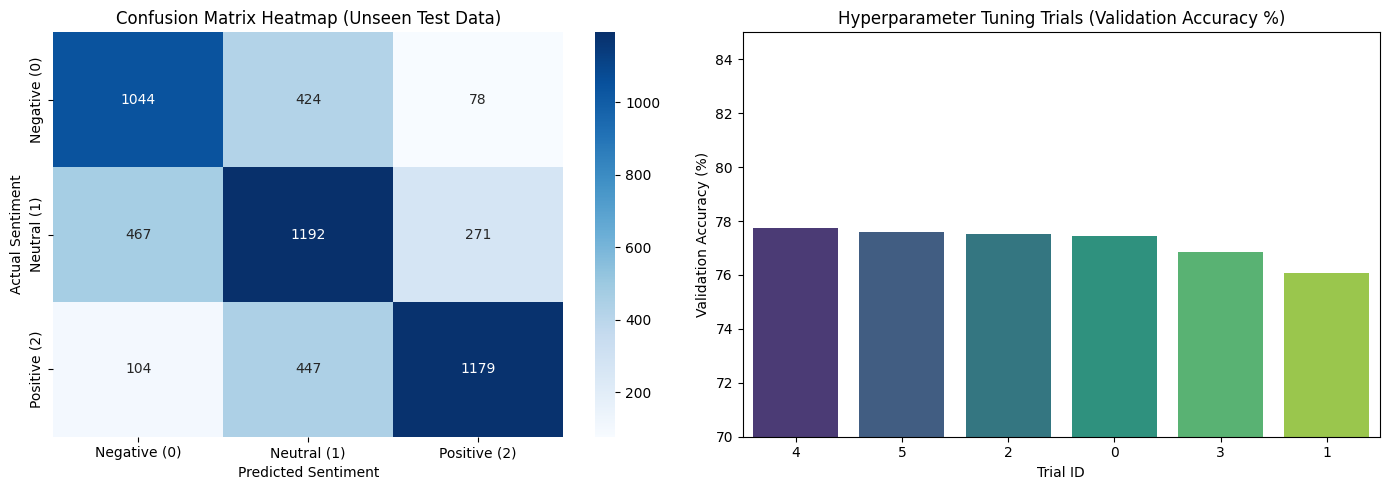


================== DETAILED CLASSIFICATION REPORT ==================
              precision    recall  f1-score   support

Negative (0)       0.65      0.68      0.66      1546
 Neutral (1)       0.58      0.62      0.60      1930
Positive (2)       0.77      0.68      0.72      1730

    accuracy                           0.66      5206
   macro avg       0.67      0.66      0.66      5206
weighted avg       0.66      0.66      0.66      5206



In [8]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# Predict sentiment classes on the unseen test dataset using the best model
y_pred_probs = best_model.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

# Create a side-by-side figure with 2 plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Confusion Matrix Heatmap (Shows True vs Predicted Labels)
cm = confusion_matrix(y_test, y_pred)
class_names = ['Negative (0)', 'Neutral (1)', 'Positive (2)']
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title('Confusion Matrix Heatmap (Unseen Test Data)')
axes[0].set_xlabel('Predicted Sentiment')
axes[0].set_ylabel('Actual Sentiment')

# Plot 2: Hyperparameter Trial Validation Accuracy Comparison
sns.barplot(data=df_trials, x='Trial ID', y='Val Accuracy (%)', hue='Trial ID', palette='viridis', legend=False, ax=axes[1])
axes[1].set_title('Hyperparameter Tuning Trials (Validation Accuracy %)')
axes[1].set_ylim(70, 85)
axes[1].set_ylabel('Validation Accuracy (%)')
axes[1].set_xlabel('Trial ID')

# Display the plots cleanly
plt.tight_layout()
plt.show()

# Print detailed Precision, Recall, and F1-Score report for each class
print("\n================== DETAILED CLASSIFICATION REPORT ==================")
print(classification_report(y_test, y_pred, target_names=class_names))